In [10]:
import numpy as np
import pandas as pd
from sklearn.metrics import pairwise_distances
import matplotlib.pyplot as plt

In [3]:
df_particles = pd.read_csv('particle_info_all.csv')
del df_particles['Unnamed: 0']
df_particles

,map_x,map_y,size,area,perimeter,circularity,id,id_file
0,17643.790,3377.0300,5.526773,23.647840,18.651930,0.853910,MF_L_01_Mosaic 2_1_1,MF_L_01
1,17539.190,3413.8140,6.491021,30.939370,23.863780,0.682497,MF_L_01_Mosaic 2_1_2,MF_L_01
2,17550.630,3434.4600,1.879904,2.778985,6.338905,0.868812,MF_L_01_Mosaic 2_1_3,MF_L_01
3,17173.330,3375.5150,2.730839,5.915268,9.250415,0.868401,MF_L_01_Mosaic 2_2_1,MF_L_01
4,17195.590,3419.5390,2.188061,3.784713,7.719111,0.797933,MF_L_01_Mosaic 2_2_2,MF_L_01
...,...,...,...,...,...,...,...,...
46737,-7312.458,853.6571,3.080208,7.119494,10.131080,0.871376,KC_N_02_Mosaic 2_1079_2,KC_N_02
46738,-7369.397,866.1425,6.080893,23.489040,21.435460,0.642196,KC_N_02_Mosaic 2_1079_3,KC_N_02
46739,-7364.972,895.0653,0.727432,0.370531,2.221408,0.943271,KC_N_02_Mosaic 2_1079_4,KC_N_02
46740,-7378.455,909.1148,1.675618,2.104089,5.783553,0.790210,KC_N_02_Mosaic 2_1079_5,KC_N_02


In [4]:
df_matches = pd.read_csv('results_raman/matches_all_raman.csv')
del df_matches['Unnamed: 0']
df_matches = df_matches.query('hqi_stearates > .7').loc[:,['map_x', 'map_y', 'id', 'hqi_stearates']].reset_index(drop=True)
df_matches_info = np.array([x.split('_')[:3] for x in df_matches.loc[:,'id']])
df_matches['id_file'] = [x[0]+'_'+x[1]+'_'+x[2] for x in df_matches_info]
id_file_list = np.unique(df_matches['id_file'])
df_matches

,map_x,map_y,id,hqi_stearates,id_file
0,16151.950195,5081.500000,KC_L_02_0425_1,0.809885,KC_L_02
1,16101.900391,5082.899902,KC_L_02_0425_2,0.891150,KC_L_02
2,16103.750000,5099.100098,KC_L_02_0425_6,0.922769,KC_L_02
3,16101.500000,5098.950195,KC_L_02_0425_7,0.892321,KC_L_02
4,16107.400391,5100.350098,KC_L_02_0425_8,0.869911,KC_L_02
...,...,...,...,...,...
652,-4543.500000,-1759.750000,KC_N_02_0328_28,0.980794,KC_N_02
653,-4501.899902,-1758.099976,KC_N_02_0328_29,0.959347,KC_N_02
654,-4510.850098,-1747.099976,KC_N_02_0328_30,0.742729,KC_N_02
655,-4511.100098,-1743.050049,KC_N_02_0328_31,0.995632,KC_N_02


In [11]:
df_list = []
for id_file in id_file_list:
    df_matches_file = df_matches.query('id_file in @id_file').reset_index(drop=True)
    df_particles_file = df_particles.query('id_file in @id_file').reset_index(drop=True)
    coords_matches = df_matches_file.loc[:,['map_x', 'map_y']]
    coords_particles = df_particles_file.loc[:,['map_x', 'map_y']]

    id_matches = np.argmin(pairwise_distances(coords_matches,
                       coords_particles), axis=1)

    df_particles_matches = df_particles_file.iloc[id_matches, :].reset_index(drop=True)
    df_particles_matches = df_particles_matches.drop('id_file', axis=1)
    df_particles_matches = df_particles_matches.rename({'map_x':'map_x_p',
                                 'map_y':'map_y_p',
                                 'id':'id_p',
                                 #'id_file':'id_file_p'
                                }, axis=1)


    df_matches_file = pd.concat([df_matches_file, 
                                 df_particles_matches], axis=1)

    df_matches_file['distance'] = np.sqrt((df_matches_file['map_x'] - df_matches_file['map_x_p']) ** 2 + 
                                          (df_matches_file['map_y'] - df_matches_file['map_y_p']) ** 2)

    df_list.append(df_matches_file)

(array([616.,   8.,  11.,   1.,   3.,  12.,   4.,   1.,   0.,   1.]),
 array([4.26163641e-02, 1.47655721e+01, 2.94885279e+01, 4.42114837e+01,
        5.89344395e+01, 7.36573953e+01, 8.83803510e+01, 1.03103307e+02,
        1.17826263e+02, 1.32549218e+02, 1.47272174e+02]),
 <BarContainer object of 10 artists>)

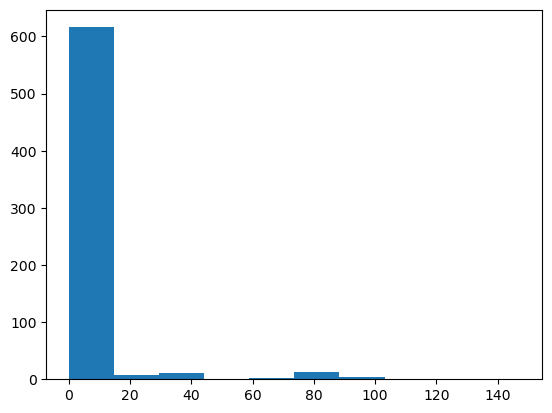

In [12]:
df_matches_particle = pd.concat(df_list, axis=0).reset_index(drop=True)
plt.hist(df_matches_particle['distance'])#.drop('id_file',axis=1)

In [89]:
ids_p_file = [np.where(df_matches_particle['id_file'] == x)[0] for x in id_file_list]
np.random.seed(10)
idx_rand_check = np.concatenate([np.random.choice(x, int(x.shape[0]/10), replace=False) for x in ids_p_file])
idx_rand_check

array([ 19,  14,  43,  37,  66,   3,  80,  41,  38, 158, 104, 119, 114,
       151, 118, 164, 154, 168, 259, 269, 216, 226, 198, 193, 262, 272,
       298, 325, 295, 324, 329, 337, 360, 338, 404, 405, 391, 384, 437,
       426, 415, 480, 479, 440, 416, 501, 543, 517, 547, 526, 527, 599,
       581, 572, 570, 579, 643, 622, 632, 626])

In [91]:
df_rand_check = df_matches_particle.iloc[idx_rand_check,:].reset_index(drop=True)
df_rand_check.to_csv('random_check_particles.csv')
df_rand_check

,map_x,map_y,id,hqi_stearates,id_file,map_x_p,map_y_p,size,area,perimeter,circularity,id_p,distance
0,19731.400391,-1368.599976,FB_L_01_0411_22,0.994030,FB_L_01,19731.6400,-1368.88900,1.977432,2.849103,8.566628,0.487673,FB_L_01_Mosaic 1_143_11,0.375430
1,19717.099609,-1385.099976,FB_L_01_0411_16,0.989928,FB_L_01,19717.3400,-1385.31300,2.053668,3.391386,8.077599,0.652910,FB_L_01_Mosaic 1_143_4,0.321196
2,19985.500000,-721.200012,FB_L_01_0411_49,0.990784,FB_L_01,19985.7200,-721.48970,1.186246,1.067619,4.084815,0.803734,FB_L_01_Mosaic 3_138_14,0.363757
3,19993.550781,-728.400024,FB_L_01_0411_42,0.989607,FB_L_01,19993.8000,-728.82170,1.132942,0.968059,3.723228,0.877210,FB_L_01_Mosaic 3_138_7,0.489817
4,19597.650391,37.099998,FB_L_01_0411_75,0.936848,FB_L_01,19597.2300,37.18329,0.701340,0.249959,2.621555,0.456868,FB_L_01_Mosaic 4_128_2,0.428562
5,19809.349609,-1397.849976,FB_L_01_0411_4,0.994717,FB_L_01,19809.5500,-1398.11100,2.365152,4.175154,8.306324,0.760143,FB_L_01_Mosaic 1_149_4,0.329075
6,19598.900391,55.900002,FB_L_01_0411_90,0.987361,FB_L_01,19598.6400,56.06850,2.043029,3.253697,7.042917,0.823972,FB_L_01_Mosaic 4_128_19,0.310153
7,20030.300781,-723.549988,FB_L_01_0411_47,0.931294,FB_L_01,20030.3400,-723.82640,1.066960,0.898156,3.532624,0.904061,FB_L_01_Mosaic 3_138_12,0.279181
8,19985.449219,-726.650024,FB_L_01_0411_44,0.992960,FB_L_01,19985.7100,-726.36930,1.169516,1.065501,3.938872,0.862682,FB_L_01_Mosaic 3_138_9,0.383162
9,18374.099609,-1282.550049,FB_L_02_0416_36,0.983927,FB_L_02,18374.2400,-1282.59500,3.969640,12.347520,15.609550,0.636561,FB_L_02_Mosaic 1_430_18,0.147411
